# Sugar Scan - Diabete Disease Predicition

In [42]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

Find the file path

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##1. Load  the Data

In [10]:
import pandas as pd

file_path = "/content/drive/MyDrive/machine learning projects/diabetes.csv"

diabete_df = pd.read_csv(file_path)
diabete_df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# 2. Get Data

In [11]:
file_path = "/content/drive/MyDrive/machine learning projects/diabetes.csv"

diabete_df = pd.read_csv(file_path)
diabete_df.head(6)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0


#3. Proprocess Data

In [13]:
diabete_df.shape

(768, 9)

In [14]:
diabete_df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


In [15]:
diabete_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [16]:
diabete_df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [17]:
diabete_df.groupby('Outcome').mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,109.980000,68.184000,19.664000,68.792000,30.304200,0.429734,31.190000
1,4.865672,141.257463,70.824627,22.164179,100.335821,35.142537,0.550500,37.067164


#4. Separate Dependent & Independ Feature into x and y

In [18]:
X = diabete_df.drop('Outcome',axis=1)
y = diabete_df['Outcome']

In [19]:
print(X)

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6      148             72             35        0  33.6   
1              1       85             66             29        0  26.6   
2              8      183             64              0        0  23.3   
3              1       89             66             23       94  28.1   
4              0      137             40             35      168  43.1   
..           ...      ...            ...            ...      ...   ...   
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  
0                       0.627   50  
1                       0.351   31  


In [20]:
print(y)

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64


#5. Standarization

In [21]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X)
Standard_data = scaler.fit_transform(X)
X = Standard_data

In [22]:
X

array([[ 0.63994726,  0.84832379,  0.14964075, ...,  0.20401277,
         0.46849198,  1.4259954 ],
       [-0.84488505, -1.12339636, -0.16054575, ..., -0.68442195,
        -0.36506078, -0.19067191],
       [ 1.23388019,  1.94372388, -0.26394125, ..., -1.10325546,
         0.60439732, -0.10558415],
       ...,
       [ 0.3429808 ,  0.00330087,  0.14964075, ..., -0.73518964,
        -0.68519336, -0.27575966],
       [-0.84488505,  0.1597866 , -0.47073225, ..., -0.24020459,
        -0.37110101,  1.17073215],
       [-0.84488505, -0.8730192 ,  0.04624525, ..., -0.20212881,
        -0.47378505, -0.87137393]], shape=(768, 8))

#6. Train test split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=25, random_state=1)

#7. Train Model

In [24]:
from sklearn.linear_model import LogisticRegression
lg = LogisticRegression()

In [25]:
model = svm.SVC(kernel='linear')

In [26]:
lg.fit(X_train,y_train)

LogisticRegression()

In [27]:
train_y_pred = lg.predict(X_train)
test_y_pred = lg.predict(X_test)

# Accuracy

In [28]:
print('Train set Accuracy :',accuracy_score(train_y_pred,y_train))
print('Test set Accuracy :',accuracy_score(test_y_pred,y_test))

Train set Accuracy : 0.7792732166890982
Test set Accuracy : 0.84


# Prediction System

In [36]:
patients = [
    (6,148,72,35,0,33.6,0.627,50),
    (1,85,66,29,0,26.6,0.351,31),
    (8,183,64,0,0,23.3,0.672,32),
    (10,168,74,0,0,38.0,0.537,34)
]

for i, patient in enumerate(patients):
    input_data = np.asarray(patient).reshape(1,-1)

    input_data = scaler.transform(input_data)

    prediction = lg.predict(input_data)
    probability = lg.predict_proba(input_data)

    print("Patient", i+1)
    print("Diabetes probability:", round(probability[0][1]*100,2), "%")

    if prediction[0] == 1:
        print("Result: Has diabetes")
    else:
        print("Result: Does not have diabetes")

    print("----------------")

Patient 1
Diabetes probability: 71.38 %
Result: Has diabetes
----------------
Patient 2
Diabetes probability: 5.12 %
Result: Does not have diabetes
----------------
Patient 3
Diabetes probability: 78.9 %
Result: Has diabetes
----------------
Patient 4
Diabetes probability: 89.2 %
Result: Has diabetes
----------------


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [32]:
diabete_df.head(100)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
95,6,144,72,27,228,33.9,0.255,40,0
96,2,92,62,28,0,31.6,0.130,24,0
97,1,71,48,18,76,20.4,0.323,22,0
98,6,93,50,30,64,28.7,0.356,23,0


# Confusion Matrix

[[17  0]
 [ 4  4]]


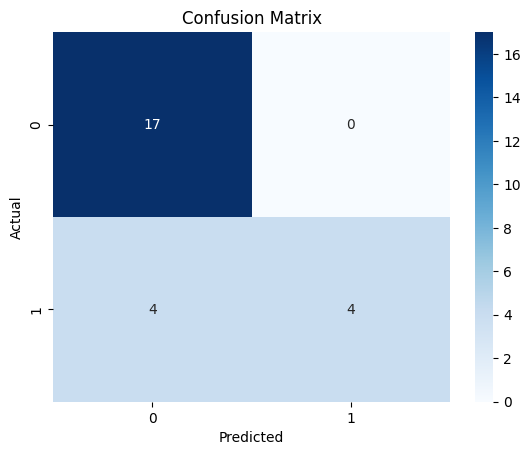

In [38]:
cm = confusion_matrix(y_test, test_y_pred)

print(cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

# Precision, Recall, F1-score

In [40]:
from sklearn.metrics import classification_report

print(classification_report(y_test, test_y_pred))

              precision    recall  f1-score   support

           0       0.81      1.00      0.89        17
           1       1.00      0.50      0.67         8

    accuracy                           0.84        25
   macro avg       0.90      0.75      0.78        25
weighted avg       0.87      0.84      0.82        25



In [41]:
models = {
    "Logistic Regression": LogisticRegression(),
    "SVM": svm.SVC(kernel='linear'),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1)
}


for name, model in models.items():

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    accuracy = accuracy_score(y_test, prediction)

    print(name, "Accuracy :", accuracy)

Logistic Regression Accuracy : 0.84
SVM Accuracy : 0.84
Random Forest Accuracy : 0.76


# Compare using a table

In [43]:
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test,pred)
    ])


comparison = pd.DataFrame(
    results,
    columns=["Model","Accuracy"]
)

comparison

,Model,Accuracy
0,Logistic Regression,0.84
1,SVM,0.84
2,Random Forest,0.76
